In [110]:
import pandas as pd
import numpy as np

In [111]:
# Load Dataset
df = pd.read_csv(
    r"C:\Users\HP\Desktop\Project\fake reviews dataset.csv\fake reviews dataset.csv", engine="python", on_bad_lines='skip'
)

In [112]:
# Basic Overview
print(df.head())
print(df.tail())

             category  rating label  \
0  Home_and_Kitchen_5     5.0    CG   
1  Home_and_Kitchen_5     5.0    CG   
2  Home_and_Kitchen_5     5.0    CG   
3  Home_and_Kitchen_5     1.0    CG   
4  Home_and_Kitchen_5     5.0    CG   

                                               text_  
0  Love this!  Well made, sturdy, and very comfor...  
1  love it, a great upgrade from the original.  I...  
2  This pillow saved my back. I love the look and...  
3  Missing information on how to use it, but it i...  
4  Very nice set. Good quality. We have had the s...  
                           category  rating label  \
40427  Clothing_Shoes_and_Jewelry_5     4.0    OR   
40428  Clothing_Shoes_and_Jewelry_5     5.0    CG   
40429  Clothing_Shoes_and_Jewelry_5     2.0    OR   
40430  Clothing_Shoes_and_Jewelry_5     1.0    CG   
40431  Clothing_Shoes_and_Jewelry_5     5.0    OR   

                                                   text_  
40427  I had read some reviews saying that this bra r... 

In [113]:
print("Shape:", df.shape)
print("Columns:", df.columns)

Shape: (40432, 4)
Columns: Index(['category', 'rating', 'label', 'text_'], dtype='str')


In [71]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  str    
 1   rating    40432 non-null  float64
 2   label     40432 non-null  str    
 3   text_     40432 non-null  str    
dtypes: float64(1), str(3)
memory usage: 1.2 MB
None


In [72]:
# Missing Values
print(df.isnull().sum())

category    0
rating      0
label       0
text_       0
dtype: int64


In [73]:
# Statistics
print(df.describe())

             rating
count  40432.000000
mean       4.256579
std        1.144354
min        1.000000
25%        4.000000
50%        5.000000
75%        5.000000
max        5.000000


In [74]:
# Data Types
print(df.dtypes)

category        str
rating      float64
label           str
text_           str
dtype: object


In [75]:
# Unique Values
print(df.nunique())

category       10
rating          5
label           2
text_       40412
dtype: int64


In [76]:
# Label Distribution
print("\nLabel Distribution:")
print(df['label'].value_counts())


Label Distribution:
label
CG    20216
OR    20216
Name: count, dtype: int64


In [77]:
#Label distribution graph
import matplotlib.pyplot as plt

<Axes: xlabel='label'>

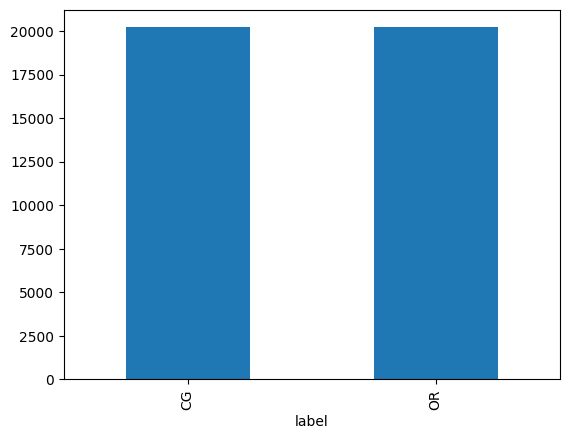

In [78]:
df['label'].value_counts().plot(kind='bar')

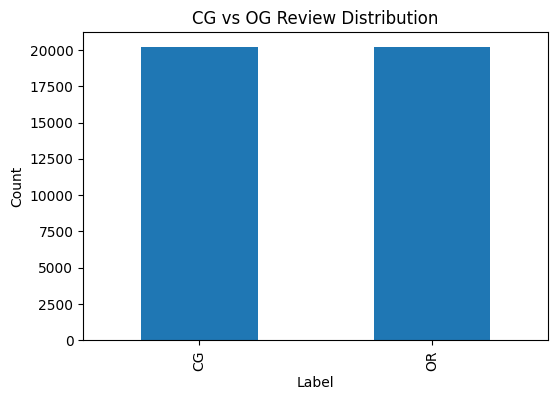

In [79]:
plt.figure(figsize=(6,4))
df['label'].value_counts().plot(kind='bar')
plt.title("CG vs OG Review Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

In [80]:
#Data Cleaning
df = df.drop_duplicates()
df = df.dropna()

In [81]:
#Train-Test Split
from sklearn.model_selection import train_test_split

In [82]:
X = df['text_']
y = df['label']

In [83]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [84]:
#TF-IDF
#features extraction
from sklearn.feature_extraction.text import TfidfVectorizer

In [85]:
df['review_length'] = df['text_'].apply(len)
df['word_count'] = df['text_'].apply(lambda x: len(str(x).split()))
df['avg_word_length'] = df['text_'].apply(lambda x: np.mean([len(w) for w in str(x).split()]))
df['punctuation_count'] = df['text_'].apply(lambda x: sum([1 for c in str(x) if c in '!?.,']))

In [86]:
df.head()

,category,rating,label,text_,review_length,word_count,avg_word_length,punctuation_count
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor...",75,12,5.166667,5
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I...",80,16,4.000000,2
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...,67,14,3.857143,2
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i...",81,17,3.764706,2
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...,85,18,3.777778,2


In [87]:
df['label'].value_counts()

label
OR    20215
CG    20205
Name: count, dtype: int64

In [88]:
tfidf = TfidfVectorizer()

In [89]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [90]:
print(X_train_tfidf.shape)

(32336, 36893)


In [91]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression

In [92]:
#model building
model = LogisticRegression()

In [93]:
model.fit(X_train_tfidf, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [94]:
#Prediction
y_pred = model.predict(X_test_tfidf)

In [95]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_tfidf, y_train)

print(hasattr(model, "coef_"))

True


In [96]:
#Accuracy + Metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [97]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9051212271152894


In [98]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

          CG       0.91      0.90      0.90      4055
          OR       0.90      0.91      0.91      4029

    accuracy                           0.91      8084
   macro avg       0.91      0.91      0.91      8084
weighted avg       0.91      0.91      0.91      8084



In [99]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[3636  419]
 [ 348 3681]]


In [100]:
#Confusion Matrix Graph
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

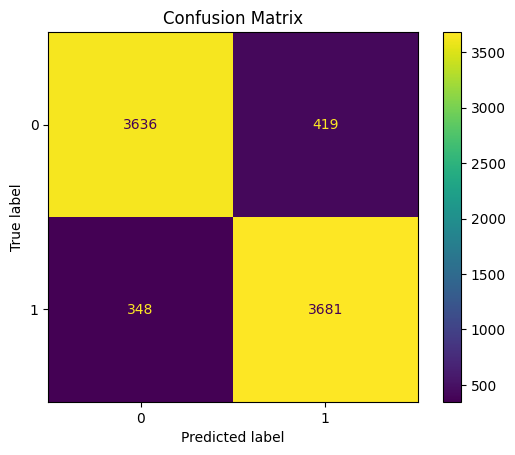

In [101]:
cm=confusion_matrix(y_test,y_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [102]:
print(model)
print(hasattr(model, "coef_"))

LogisticRegression()
True


In [104]:
print(model.classes_)

['CG' 'OR']


In [117]:
real_df = pd.read_csv(
    r"C:\Users\HP\Desktop\Project\fake reviews dataset.csv\fake reviews dataset.csv",
    engine="python",
    on_bad_lines="skip"
)

print(real_df.columns)

real_reviews = real_df["text_"].fillna("").astype(str)

real_tfidf = tfidf.transform(real_reviews)

predictions = model.predict(real_tfidf)

real_df["Prediction"] = predictions

print(real_df[["text_", "Prediction"]].head(10))

Index(['category', 'rating', 'label', 'text_'], dtype='str')
                                               text_ Prediction
0  Love this!  Well made, sturdy, and very comfor...         CG
1  love it, a great upgrade from the original.  I...         CG
2  This pillow saved my back. I love the look and...         CG
3  Missing information on how to use it, but it i...         CG
4  Very nice set. Good quality. We have had the s...         CG
5       I WANTED DIFFERENT FLAVORS BUT THEY ARE NOT.         OR
6  They are the perfect touch for me and the only...         CG
7  These done fit well and look great.  I love th...         CG
8  Great big numbers & easy to read, the only thi...         CG
9  My son loves this comforter and it is very wel...         CG
